# Feature Engineering and Exploratory Data Analysis

This notebook continues from `01_import_eda_cleaning.ipynb`, picking up where that notebook left off: a cleaned version of the British Airways review dataset, exported to `data/processed/cleaned_dataset.csv`.

The goals here are to engineer a few derived feature columns (e.g. review length, date-based features), explore the cleaned data visually, and draw out some findings.

## Contents
1. Loading the Cleaned Dataset
2. Restoring Data Types Lost in CSV Export
3. Feature Engineering
4. Exploratory Data Analysis and Visualizations

## 1. Loading the Cleaned Dataset

Importing the core libraries and reading in the already-cleaned CSV produced at the end of notebook 1, rather than repeating the raw-data cleaning steps here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal

In [2]:
df = pd.read_csv('../data/processed/cleaned_dataset.csv')
print(df.head())

                                             reviews        date  \
0  I had the most fantastic BA Flight today. The ...  2023-08-01   
1  Couldn’t book in online. Arrived at check in t...  2023-07-31   
2  London Heathrow to Mumbai in a Boeing 787-8 in...  2023-07-31   
3  Keflavík, Iceland to London Heathrow on an A32...  2023-07-31   
4  Terrible Experience with British Airways. I bo...  2023-07-29   

          country       seat_type recommended  stars                  route  \
0       Hong Kong  Business Class         yes      5  Heathrow to Las Vegas   
1  United Kingdom   Economy Class          no      3       Rome to Heathrow   
2         Iceland  Business Class         yes      3      Gatwick to Venice   
3         Iceland  Business Class         yes      5       London to Luanda   
4          Canada   Economy Class          no      5     Denver to Heathrow   

  type_of_traveller is_verified  
0    Family Leisure        True  
1      Solo Leisure        True  
2      Solo Le

In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   reviews            2500 non-null   str   
 1   date               2500 non-null   str   
 2   country            2500 non-null   str   
 3   seat_type          2500 non-null   str   
 4   recommended        2500 non-null   str   
 5   stars              2500 non-null   int64 
 6   route              2500 non-null   str   
 7   type_of_traveller  2500 non-null   str   
 8   is_verified        2092 non-null   object
dtypes: int64(1), object(1), str(7)
memory usage: 175.9+ KB
None


## 2. Restoring Data Types Lost in CSV Export

CSV files are plain text and don't store dtype metadata, so columns that were carefully typed in notebook 1 (`date` as `datetime64`, `is_verified` as a nullable boolean) come back as generic text/object types after a round trip through `to_csv()` / `read_csv()`. `df.info()` confirms this: `date` is back to `str`, and `is_verified` is `object` with only 2092 non-null values recognized.

Both are restored here: `date` is re-parsed with `pd.to_datetime()` (no `format='mixed'` needed this time, since the exported CSV already has a single consistent date format), and `is_verified` is re-cast with `.astype('boolean')`. The restored `is_verified` value counts (True: 1861, False: 231, `<NA>`: 408) match exactly what was computed in notebook 1, confirming nothing was lost in the round trip — only the dtype needed reapplying.

In [4]:
df['date'] = pd.to_datetime(df['date'])
print(df['date'].head())



0   2023-08-01
1   2023-07-31
2   2023-07-31
3   2023-07-31
4   2023-07-29
Name: date, dtype: datetime64[us]


In [5]:
df['is_verified'] = df['is_verified'].astype('boolean')
print(df['is_verified'].value_counts(dropna=False))

is_verified
True     1861
<NA>      408
False     231
Name: count, dtype: Int64


## 3. Feature Engineering

### 3.1 Date-Based Features

Using the `.dt` accessor on the now-restored `date` column to pull out `year`, `month` (numeric, for sorting/plotting in calendar order), and `month_name` (a readable string, for labels) as separate columns.

In [6]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()
print(df[['date', 'year', 'month', 'month_name']].head())

        date  year  month month_name
0 2023-08-01  2023      8     August
1 2023-07-31  2023      7       July
2 2023-07-31  2023      7       July
3 2023-07-31  2023      7       July
4 2023-07-29  2023      7       July


In [7]:
print(df['month'].unique())

[ 8  7  6  5  4  3  2  1 12 11 10  9]


In [8]:
print(df.head())

                                             reviews       date  \
0  I had the most fantastic BA Flight today. The ... 2023-08-01   
1  Couldn’t book in online. Arrived at check in t... 2023-07-31   
2  London Heathrow to Mumbai in a Boeing 787-8 in... 2023-07-31   
3  Keflavík, Iceland to London Heathrow on an A32... 2023-07-31   
4  Terrible Experience with British Airways. I bo... 2023-07-29   

          country       seat_type recommended  stars                  route  \
0       Hong Kong  Business Class         yes      5  Heathrow to Las Vegas   
1  United Kingdom   Economy Class          no      3       Rome to Heathrow   
2         Iceland  Business Class         yes      3      Gatwick to Venice   
3         Iceland  Business Class         yes      5       London to Luanda   
4          Canada   Economy Class          no      5     Denver to Heathrow   

  type_of_traveller  is_verified  year  month month_name  
0    Family Leisure         True  2023      8     August  
1   

### 3.2 Review Length

A `review_length` column is added, counting the number of words in each review (via `.str.split().str.len()`, splitting on whitespace and counting the resulting list). A sanity check with `.describe()` shows a minimum of 23 words and a maximum of 654, with no zero-length reviews — consistent with `reviews` having no missing values.

In [9]:
df['review_length'] = df['reviews'].str.split().str.len()
print(df['review_length'].head())

0    187
1     68
2    119
3    117
4    639
Name: review_length, dtype: int64


In [10]:
print(df['review_length'].describe())

count    2500.000000
mean      166.066800
std       111.622362
min        23.000000
25%        87.000000
50%       137.000000
75%       208.250000
max       654.000000
Name: review_length, dtype: float64


In [11]:
print(df.head())

                                             reviews       date  \
0  I had the most fantastic BA Flight today. The ... 2023-08-01   
1  Couldn’t book in online. Arrived at check in t... 2023-07-31   
2  London Heathrow to Mumbai in a Boeing 787-8 in... 2023-07-31   
3  Keflavík, Iceland to London Heathrow on an A32... 2023-07-31   
4  Terrible Experience with British Airways. I bo... 2023-07-29   

          country       seat_type recommended  stars                  route  \
0       Hong Kong  Business Class         yes      5  Heathrow to Las Vegas   
1  United Kingdom   Economy Class          no      3       Rome to Heathrow   
2         Iceland  Business Class         yes      3      Gatwick to Venice   
3         Iceland  Business Class         yes      5       London to Luanda   
4          Canada   Economy Class          no      5     Denver to Heathrow   

  type_of_traveller  is_verified  year  month month_name  review_length  
0    Family Leisure         True  2023      8   

## 4. Exploratory Data Analysis and Visualizations

### 4.1 Review Length Distribution

A histogram of `review_length` (in words), with a KDE curve overlaid to smooth out the shape. The distribution is right-skewed: most reviews fall somewhere in the 50-200 word range, with a long tail of longer, more detailed reviews stretching out past 600 words.

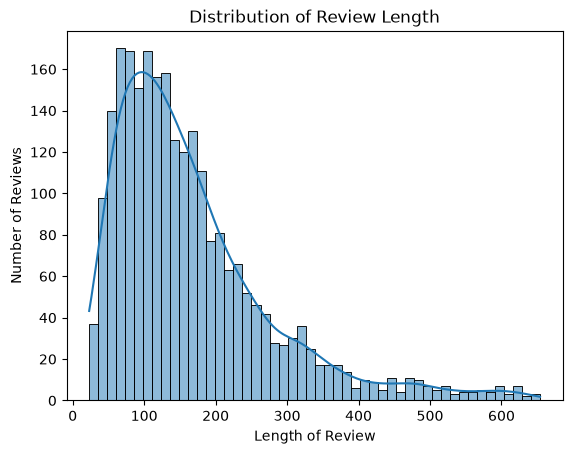

In [12]:
plt.figure()
sns.histplot(
    data=df,
    x='review_length',
    bins=50,
    kde=True
)
plt.xlabel('Length of Review')
plt.ylabel('Number of Reviews')
plt.title('Distribution of Review Length')
plt.show()

### 4.2 Average Star Rating Over Time

Reviews are grouped by `year` (via `df.groupby('year')['stars'].mean()`) to compute one average `stars` value per year, then plotted as a line chart.

The y-axis is deliberately set to `plt.ylim(1, 10)` — the full scale `stars` is meant to represent — rather than letting matplotlib auto-scale to the narrow range of the actual averages (roughly 4.25-4.31). Auto-scaling here would have visually exaggerated tiny differences between years into what looks like a dramatic, meaningful trend, when the real picture is that the average has stayed essentially flat across 2015-2023.

**Important caveat:** as established in section 5 of `01_import_eda_cleaning.ipynb`, the `stars` column only ever contains odd values (1, 3, 5, 7, 9) due to a known scraping limitation in the source dataset — even values (2, 4, 6, 8, 10) are structurally absent, not genuinely zero. This means any average computed from `stars`, including the ones in this chart, is an average of an *incomplete* version of the true ratings, not the true ratings themselves. The flat trend shown here is a reasonably safe conclusion only if that scraping limitation affected every year similarly (rather than, say, worsening in later years) — something this dataset alone can't confirm. This chart should be read as "the available (incomplete) rating data shows no meaningful change over time," not as a fully reliable statement about real customer sentiment trends.

year
2015    4.314286
2016    4.259649
2017    4.272727
2018    4.277778
2019    4.269663
2020    4.307692
2021    4.310345
2022    4.248826
2023    4.266272
Name: stars, dtype: float64


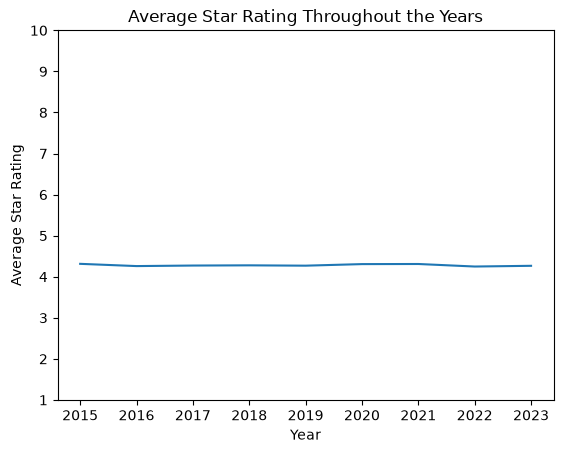

In [13]:
average_stars_per_year = df.groupby('year')['stars'].mean()
print(average_stars_per_year)
plt.plot(
    average_stars_per_year.index,
    average_stars_per_year.values
)
plt.xlabel('Year')
plt.ylabel('Average Star Rating')
plt.title('Average Star Rating Throughout the Years')
plt.ylim(1, 10)
plt.show()

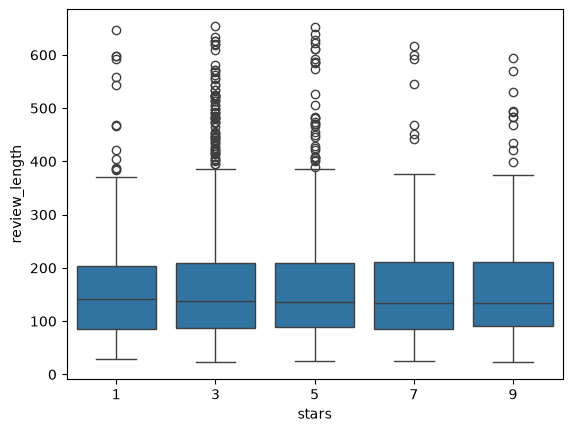

In [14]:
sns.boxplot(
    data=df,
    x='stars',
    y='review_length'
)
plt.show()

In [15]:
print(df.groupby('stars')['review_length'])

In [16]:
grouped_lengths = []
for name, group in df.groupby('stars')['review_length']:
    grouped_lengths.append(group)
print(grouped_lengths[0])

7       233
18      304
29      327
40      176
51      145
       ... 
2449    150
2460    128
2471     69
2482     68
2493    121
Name: review_length, Length: 227, dtype: int64


In [17]:
grouped_lengths = [group for name, group in df.groupby('stars')['review_length']]
print(len(grouped_lengths))

5


In [18]:
tstat, pvalue = kruskal(*grouped_lengths)
print(pvalue)

0.990598762932405


### 4.3 Testing for a Difference in Review Length Across Star Ratings

The boxplot above suggests the `review_length` distributions look similar across all five `stars` groups, but a formal test is needed to check whether that similarity holds up statistically. A Kruskal-Wallis H-test is used here rather than a one-way ANOVA, since it compares the distributions of a continuous variable across more than two independent groups without assuming the data is normally distributed — a safer choice given how right-skewed `review_length` is (see section 4.1).

Running `kruskal(*grouped_lengths)` on the five grouped `review_length` Series returns a p-value of approximately 0.991. Since this is far above the conventional significance threshold of 0.05, we fail to reject the null hypothesis that `review_length` is drawn from the same distribution across star ratings: there is no statistically significant evidence that how long a review is depends on the rating given.

**Caveat:** as with the average-rating-over-time analysis in section 4.2, this conclusion is scoped by the dataset's known scraping limitation — `stars` only ever takes the values 1, 3, 5, 7, and 9. The test is valid for the five groups it was actually run on, but it says nothing about how review length might behave at the structurally absent even-numbered ratings (2, 4, 6, 8, 10).